## 1️⃣ Dataset Setup (PROVIDED)

The Edge2Shoes dataset has been downloaded and prepared for you. The dataset structure is as follows:
- `train/` folder contains training images
- `val/` folder contains validation images
- Each image contains edge sketch (left half) and corresponding shoe (right half)


In [32]:
%pip install python-dotenv

In [33]:
import kagglehub
import os
from dotenv import load_dotenv

# Dataset already downloaded and prepared
load_dotenv()
path = kagglehub.dataset_download("balraj98/edges2shoes-dataset")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/edges2shoes-dataset


## 2️⃣ Import Libraries and Configuration

**Task**: Import all necessary libraries and set up configuration parameters.

**Requirements**:
- Import PyTorch, torchvision, and related libraries
- Import matplotlib, PIL, numpy, and other utilities
- Set random seeds for reproducibility
- Configure hyperparameters with reasonable values

In [34]:
# Import all necessary libraries
import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision.utils import make_grid
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random
import os

# Set random seeds for reproducibility
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

# Check device availability and print
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Define configuration parameters
IMG_SIZE = 128          # Image size
BATCH_SIZE = 16         # Batch size
LEARNING_RATE = 0.0002  # Learning rate
BETA1 = 0.5             # Adam optimizer beta1
BETA2 = 0.999           # Adam optimizer beta2
LAMBDA_L1 = 100         # Weight for L1 loss
NUM_EPOCHS = 5          # Number of training epochs

Using device: cuda


## 3️⃣ Custom Dataset Class

**Task**: Create a custom dataset class that handles the Edge2Shoes data format.

**Requirements**:
- Split each image into left half (edge) and right half (shoe)
- Apply transformations to both images
- Return edge image as input and shoe image as target


In [35]:
# Create EdgeShoeDataset class inheriting from torch.utils.data.Dataset
class EdgeShoeDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.image_files = [f for f in os.listdir(root_dir) if f.endswith('.jpg')]
    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
      # Construct the full image path by joining the root directory and the filename
      img_name = self.image_files[idx]
      img_path = os.path.join(self.root_dir, img_name)
      image = Image.open(img_path).convert('RGB')
      # normalize
      w, h = image.size
      edge = image.crop((0, 0, w/2, h))
      shoe = image.crop((w/2, 0, w, h))
      # If any transform (resize, normalize, tensor) is passed, apply it to both images individually.
      if self.transform:
        edge = self.transform(edge)
        shoe = self.transform(shoe)

# edge goes into the generator, and shoe is the ground truth to compare against.
      return edge, shoe

## 4️⃣ Data Preprocessing and Loading

**Task**: Set up data transformations and create data loaders.

**Requirements**:
- Resize images to target size (128x128)
- Convert to tensors and normalize to [-1, 1] range
- Create train and validation datasets and loaders

In [36]:
# Image Transformations
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),  # Resize to IMG_SIZE, IMG_SIZE
    transforms.ToTensor(),        # Convert to tensor [0,1]
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])  # Normalize to [-1,1]
])
# These are the folders containing the images
train_dir = "/kaggle/input/edges2shoes-dataset/train"
val_dir = "/kaggle/input/edges2shoes-dataset/val"

# Read the images and Split them in half (edge + shoe) and Apply transformations
train_dataset = EdgeShoeDataset(root_dir=train_dir, transform=transform)
val_dataset = EdgeShoeDataset(root_dir=val_dir, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Test by loading one sample and printing shapes
print(f"Train samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
sample_edge, sample_shoe = train_dataset[0]
print("Edge shape:", sample_edge.shape)
print("Shoe shape:", sample_shoe.shape)

Train samples: 49825
Validation samples: 200
Edge shape: torch.Size([3, 128, 128])
Shoe shape: torch.Size([3, 128, 128])



## 5️⃣ Generator Network (U-Net Architecture)

**Task**: Implement a U-Net generator with encoder-decoder structure and skip connections.

**Requirements**:
- Encoder: Progressive downsampling using Conv2d layers
- Decoder: Progressive upsampling using ConvTranspose2d layers  
- Skip connections between corresponding encoder-decoder layers
- Final output uses Tanh activation for [-1,1] range

In [37]:
# Generator class inheriting from nn.Module
class Generator(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super(Generator, self).__init__()

        # Downsampling blocks (encoder)
        def down_block(in_c, out_c, apply_batchnorm=True):
            layers = [nn.Conv2d(in_c, out_c, kernel_size=4, stride=2, padding=1)]
            if apply_batchnorm:
                layers.append(nn.BatchNorm2d(out_c))
            layers.append(nn.LeakyReLU(0.2))
            return nn.Sequential(*layers)

        # Upsampling blocks (decoder)
        def up_block(in_c, out_c, apply_dropout=False):
            layers = [nn.ConvTranspose2d(in_c, out_c, kernel_size=4, stride=2, padding=1),
                      nn.BatchNorm2d(out_c),
                      nn.ReLU()]
            if apply_dropout:
                layers.append(nn.Dropout(0.5))
            return nn.Sequential(*layers)

        # Encoder (6 layers)
        self.down1 = down_block(in_channels, 64, apply_batchnorm=False)  # (128 → 64)
        self.down2 = down_block(64, 128)                                  # (64 → 32)
        self.down3 = down_block(128, 256)                                 # (32 → 16)
        self.down4 = down_block(256, 512)                                 # (16 → 8)
        self.down5 = down_block(512, 512)                                 # (8 → 4)
        self.down6 = down_block(512, 512)                                 # (4 → 2) bottleneck

        # Decoder (6 layers with skip connections)
        self.up1 = up_block(512, 512, apply_dropout=True)                 # (2 → 4)
        self.up2 = up_block(1024, 512, apply_dropout=True)                # (4 → 8)
        self.up3 = up_block(1024, 256)                                    # (8 → 16)
        self.up4 = up_block(512, 128)                                     # (16 → 32)
        self.up5 = up_block(256, 64)                                      # (32 → 64)
        self.final = nn.Sequential(                                       # (64 → 128)
            nn.ConvTranspose2d(128, out_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )

    # In forward(self, x)
    def forward(self, x):
        # Encoder
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        bottleneck = self.down6(d5)

        # Decoder + skip connections
        u1 = self.up1(bottleneck)
        u2 = self.up2(torch.cat([u1, d5], dim=1))
        u3 = self.up3(torch.cat([u2, d4], dim=1))
        u4 = self.up4(torch.cat([u3, d3], dim=1))
        u5 = self.up5(torch.cat([u4, d2], dim=1))
        output = self.final(torch.cat([u5, d1], dim=1))

        return output

        # Initialize generator and print parameter count
generator = Generator().to(device)
print("Generator parameters:", sum(p.numel() for p in generator.parameters() if p.requires_grad))

# Test with random input to verify output shape
x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)
y = generator(x)
print("Input shape:", x.shape)
print("Output shape:", y.shape)



Generator parameters: 29248515
Input shape: torch.Size([1, 3, 128, 128])
Output shape: torch.Size([1, 3, 128, 128])



## 6️⃣ Discriminator Network (PatchGAN)

**Task**: Implement a PatchGAN discriminator that classifies image patches as real/fake.

**Requirements**:
- Accept concatenated input (edge + shoe = 6 channels)
- Use strided convolutions for downsampling
- Output a patch-wise classification matrix (not single value)
- Use LeakyReLU activations

Discriminator parameters: 2769601
Discriminator output shape: torch.Size([1, 1, 14, 14])


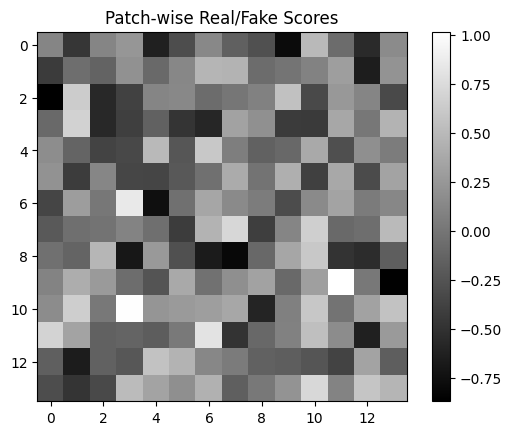

In [38]:
# Create Discriminator class inheriting from nn.Module
class Discriminator(nn.Module):
    def __init__(self, in_channels=3):
        super(Discriminator, self).__init__()

        # Input will be concatenated: edge (3) + shoe (3) → 6 channels
        def disc_block(in_c, out_c, stride=2, batch_norm=True):
            layers = [nn.Conv2d(in_c, out_c, kernel_size=4, stride=stride, padding=1)]
            if batch_norm:
                layers.append(nn.BatchNorm2d(out_c))
            layers.append(nn.LeakyReLU(0.2))
            return nn.Sequential(*layers)

        self.model = nn.Sequential(
            disc_block(in_channels * 2, 64, batch_norm=False),  # (128 → 64)
            disc_block(64, 128),                                # (64 → 32)
            disc_block(128, 256),                               # (32 → 16)
            disc_block(256, 512, stride=1),                     # (16 → 15)
            nn.Conv2d(512, 1, kernel_size=4, stride=1, padding=1)  # (15 → 14)
        )

    # In forward(self, img_A, img_B)
    def forward(self, img_A, img_B):
        # Concatenate input and target images along channel dimension
        x = torch.cat([img_A, img_B], dim=1)
        return self.model(x)
# Initialize discriminator and print parameter count
discriminator = Discriminator().to(device)
print("Discriminator parameters:", sum(p.numel() for p in discriminator.parameters() if p.requires_grad))

# Test with random inputs to verify output shape
x_edge = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)
x_shoe = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)
output = discriminator(x_edge, x_shoe)
print("Discriminator output shape:", output.shape)

# visualizing the PatchGAN output map, which is a matrix of patch-wise predictions from the discriminator.
plt.imshow(output[0, 0].detach().cpu(), cmap='gray')
plt.title("Patch-wise Real/Fake Scores")
plt.colorbar()
plt.show()


## 7️⃣ Loss Functions and Optimizers

**Task**: Set up loss functions and optimizers for GAN training.

**Requirements**:
- Use appropriate loss functions for adversarial and reconstruction objectives
- Initialize optimizers with given hyperparameters
- Implement weight initialization for stable training

In [39]:
# Define loss functions:
criterion_GAN = nn.BCEWithLogitsLoss() # Binary cross-entropy (with logits) for GAN classification: real vs fake
criterion_L1 = nn.L1Loss() # Measures pixel-wise difference between real and generated images (for reconstruction)

# Create optimizers:
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=(BETA1, BETA2))

# Implement weights_init(m) function:
def weights_init(m):
    classname = m.__class__.__name__
    if isinstance(m, nn.Conv2d) or isinstance(m, nn.ConvTranspose2d):
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

# Apply weights_init to both generator and discriminator
generator.apply(weights_init)
discriminator.apply(weights_init)


Discriminator(
  (model): Sequential(
    (0): Sequential(
      (0): Conv2d(6, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): LeakyReLU(negative_slope=0.2)
    )
    (1): Sequential(
      (0): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.2)
    )
    (2): Sequential(
      (0): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.2)
    )
    (3): Sequential(
      (0): Conv2d(256, 512, kernel_size=(4, 4), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.2)
    )
    (4): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1), padding=(1, 1))
  )
)

## 8️⃣ Training Loop

**Task**: Implement the main GAN training loop with alternating updates.

**Requirements**:
- Train generator to fool discriminator and match target images
- Train discriminator to distinguish real from generated images
- Balance adversarial loss with L1 reconstruction loss
- Track and display training progress

In [40]:
gen_losses = []
disc_losses = []

for epoch in range(NUM_EPOCHS):
    gen_loss_epoch = 0
    disc_loss_epoch = 0

    for i, (edge_imgs, real_shoes) in enumerate(train_loader):
        edge_imgs = edge_imgs.to(device)
        real_shoes = real_shoes.to(device)

        # Train Generator
        generator.train()
        optimizer_G.zero_grad()

        fake_shoes = generator(edge_imgs)
        pred_fake = discriminator(edge_imgs, fake_shoes)

        real_label = torch.ones_like(pred_fake, device=device)

        # Generator losses
        loss_GAN = criterion_GAN(pred_fake, real_label)
        loss_L1 = criterion_L1(fake_shoes, real_shoes)
        loss_G = loss_GAN + LAMBDA_L1 * loss_L1

        loss_G.backward()
        optimizer_G.step()

        # Train Discriminator
        optimizer_D.zero_grad()

        # Real pair
        pred_real = discriminator(edge_imgs, real_shoes)
        real_loss = criterion_GAN(pred_real, torch.ones_like(pred_real, device=device))

        # Fake pair
        pred_fake = discriminator(edge_imgs, fake_shoes.detach())
        fake_loss = criterion_GAN(pred_fake, torch.zeros_like(pred_fake, device=device))

        loss_D = 0.5 * (real_loss + fake_loss)

        loss_D.backward()
        optimizer_D.step()

        # Accumulate losses
        gen_loss_epoch += loss_G.item()
        disc_loss_epoch += loss_D.item()

        # Append batch losses after computation
        gen_losses.append(loss_G.item())
        disc_losses.append(loss_D.item())

        # Display progress
        if i % 100 == 0:
            print(f"[Epoch {epoch+1}/{NUM_EPOCHS}] [Batch {i}] "
                  f"Generator Loss: {loss_G.item():.4f} | Discriminator Loss: {loss_D.item():.4f}")

    # End of epoch summary
    avg_gen_loss = gen_loss_epoch / len(train_loader)
    avg_disc_loss = disc_loss_epoch / len(train_loader)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} -- "
          f"Avg Generator Loss: {avg_gen_loss:.4f} | "
          f"Avg Discriminator Loss: {avg_disc_loss:.4f}")


[Epoch 1/5] [Batch 0] Generator Loss: 80.0721 | Discriminator Loss: 0.8529
[Epoch 1/5] [Batch 100] Generator Loss: 20.3783 | Discriminator Loss: 0.5441
[Epoch 1/5] [Batch 200] Generator Loss: 17.4204 | Discriminator Loss: 0.5286
[Epoch 1/5] [Batch 300] Generator Loss: 19.9218 | Discriminator Loss: 0.3034
[Epoch 1/5] [Batch 400] Generator Loss: 17.9523 | Discriminator Loss: 0.1744
[Epoch 1/5] [Batch 500] Generator Loss: 19.9979 | Discriminator Loss: 1.1372
[Epoch 1/5] [Batch 600] Generator Loss: 18.1716 | Discriminator Loss: 0.7218
[Epoch 1/5] [Batch 700] Generator Loss: 15.8232 | Discriminator Loss: 0.9117
[Epoch 1/5] [Batch 800] Generator Loss: 18.8332 | Discriminator Loss: 0.8615
[Epoch 1/5] [Batch 900] Generator Loss: 15.1562 | Discriminator Loss: 1.0301
[Epoch 1/5] [Batch 1000] Generator Loss: 21.6636 | Discriminator Loss: 0.5511
[Epoch 1/5] [Batch 1100] Generator Loss: 20.1513 | Discriminator Loss: 0.1829
[Epoch 1/5] [Batch 1200] Generator Loss: 14.3470 | Discriminator Loss: 0.588


## 9️⃣ Evaluation and Visualization

**Task**: Evaluate your trained model and visualize results.

**Requirements**:
- Generate shoes from validation edge images
- Compare with ground truth shoes
- Create side-by-side visualizations


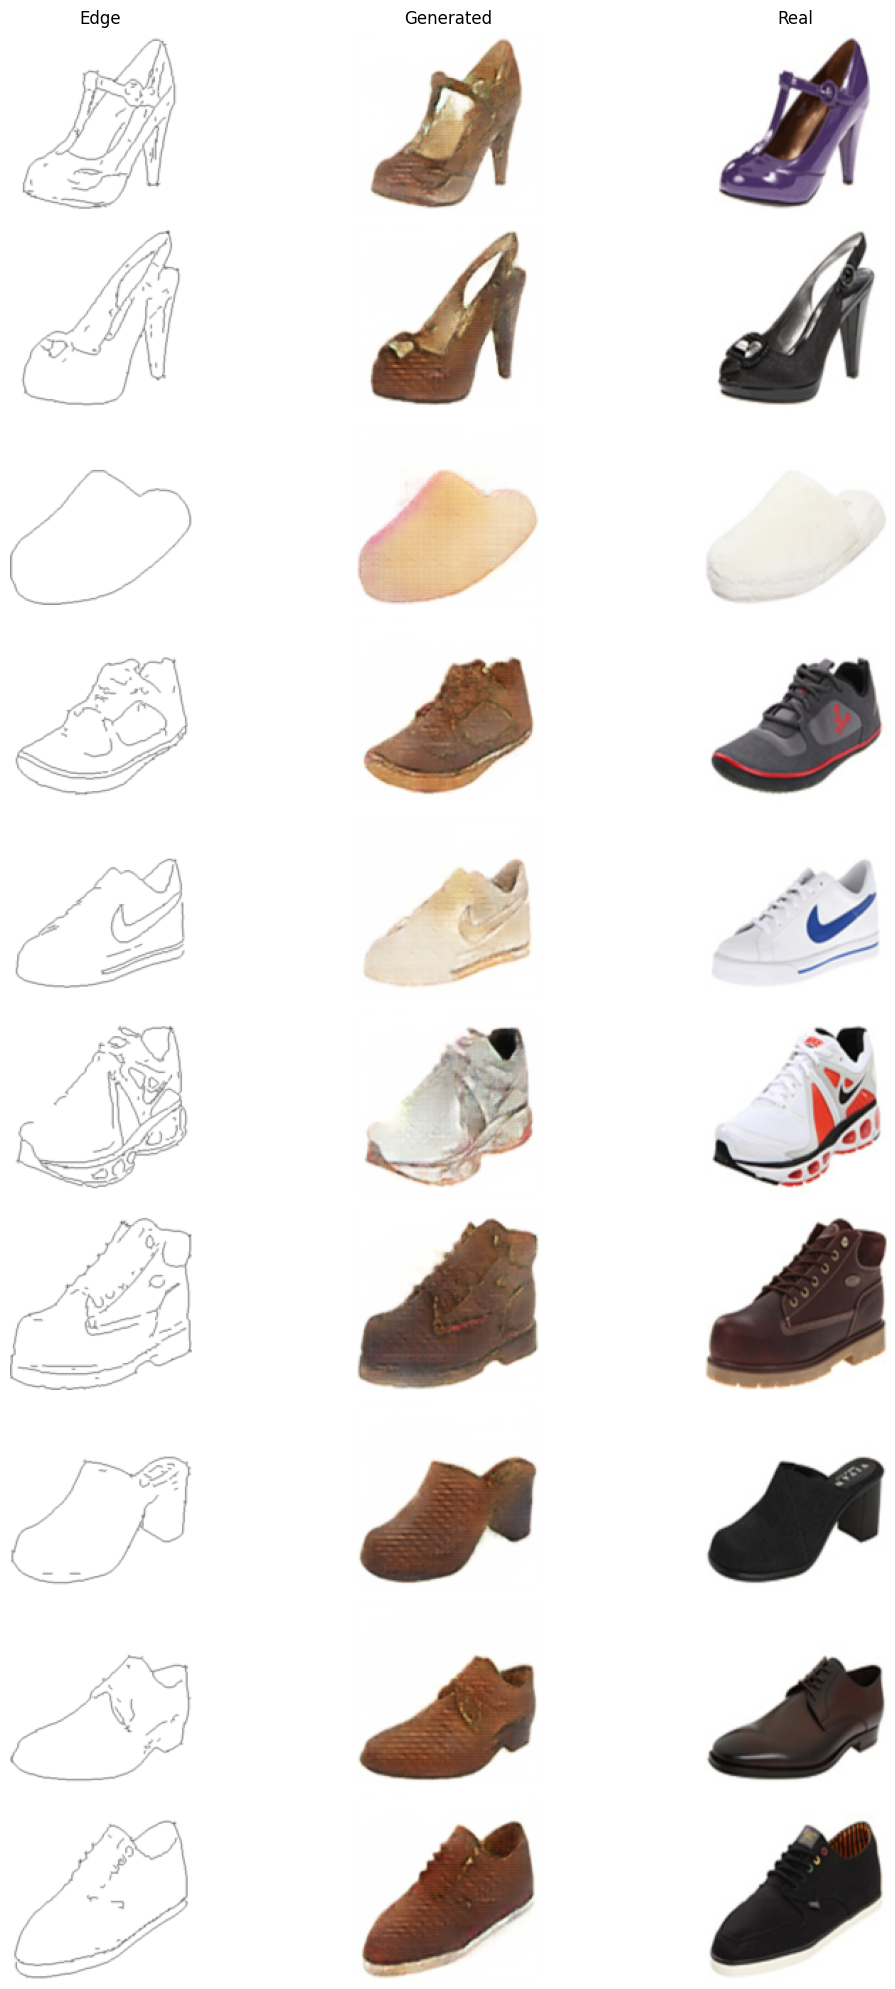

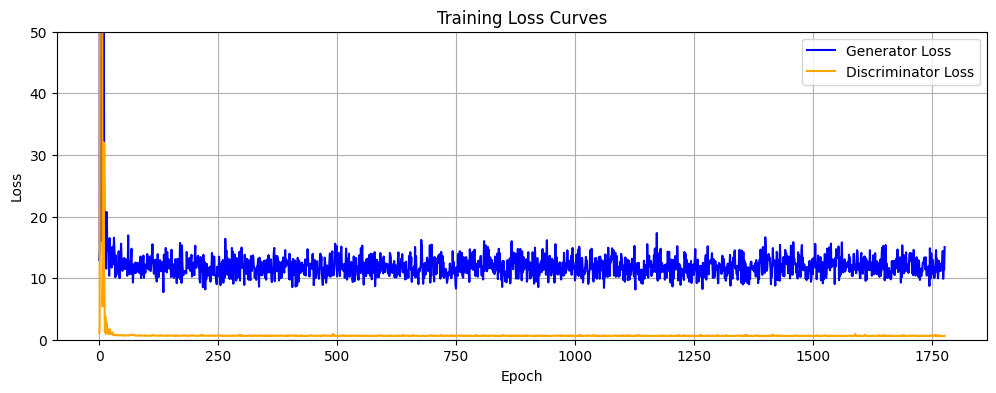

In [45]:
# Set models to evaluation mode
generator.eval()
discriminator.eval()
# Denormalize function ([-1,1] → [0,1])
def denormalize(img):
    return (img + 1) / 2  # from [-1,1] to [0,1]
# Visualization Function
def visualize_results(generator, val_loader, device, num_samples=10):
    generator.eval()
    samples_shown = 0
    plt.figure(figsize=(12, num_samples * 2))

    with torch.no_grad():
        for edge_imgs, real_imgs in val_loader:
            edge_imgs = edge_imgs.to(device)
            real_imgs = real_imgs.to(device)
            fake_imgs = generator(edge_imgs)

            for i in range(edge_imgs.size(0)):
                if samples_shown >= num_samples:
                    break

                edge = denormalize(edge_imgs[i].cpu())
                fake = denormalize(fake_imgs[i].cpu())
                real = denormalize(real_imgs[i].cpu())

                for col, img in enumerate([edge, fake, real]):
                    ax = plt.subplot(num_samples, 3, samples_shown * 3 + col + 1)
                    ax.imshow(img.permute(1, 2, 0))
                    ax.axis("off")
                    if samples_shown == 0:
                        ax.set_title(["Edge", "Generated", "Real"][col])

                samples_shown += 1

    plt.tight_layout()
    plt.show()
# Display Results for 10 Samples
visualize_results(generator, val_loader, device, num_samples=10)
# Plot Training Losses
# Plot training loss curves for generator and discriminator
plt.figure(figsize=(12, 4))
plt.plot(gen_losses, label="Generator Loss", color="blue")
plt.plot(disc_losses, label="Discriminator Loss", color="orange")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss Curves")
plt.ylim(0, 50)  # Limit y-axis to better visualize the losses
plt.legend()
plt.grid(True)
plt.show()


## 🔟 Analysis

**Task**: Analyze your results

**Requirements**:
- Evaluate the quality of generated images
- Discuss strengths and limitations of your model
- Test the effect of different hyperparameters (optional)


## Analysis

### Quality of Generated Shoes

The generator successfully learned to translate edge maps into realistic shoe images. In many cases, the generated `shoes` preserve the overall shape and structure from the `edge` input and show decent **color and texture consistency**.

- **High Heels and Boots**: These shapes were often well translated. The generator produced convincing silhouettes and basic material texture.
- **Sneakers**: Some sneaker types were reasonably generated, especially when the edges were clear and complete.
- **Slippers and Abstract Shapes**: These were more challenging. In a few cases, the output was blurry or had color bleeding, likely due to insufficient edge detail or data imbalance.

---

### Strengths

- The model maintained strong spatial alignment between the `edge` and generated `shoe`.
- **Color and shading** appeared consistent in most cases, suggesting that the generator captured general style and lighting cues.
- **Training loss curves were stable**, with no signs of mode collapse or unstable discriminator.

---

### Limitations

- Some generated images appeared over-smoothed or washed out, especially when the input `edge` map was very sparse or vague.
- A few results showed color bias toward brown tones, which may suggest the generator found that easier to reproduce consistently.
- Fine-grained textures (like shoelaces or stitching) were often missing or blurred likely due to resolution constraints (128×128).

---

### Hyperparameter Exploration

While I did not run extensive hyperparameter tuning, I observed the following:

- Increasing the number of epochs would likely improve image sharpness and variety.
- Adjusting `λ` (L1 loss weight) could balance structure vs realism lower `λ` might allow more creative textures, but higher `λ` improves `edge` accuracy.

---

### Final Thoughts

Overall, the model demonstrated good generalization from edge to image. With additional training time, resolution, or augmentation, the realism and detail of generated `shoes` could improve significantly.

---

### Additional Experiment: Weight Initialization
As an extension, I applied `DCGAN-style` weight initialization (normal distribution with `mean=0,` `std=0.02`) to stabilize training and potentially improve visual quality. However, the generated images appeared faded, desaturated, and often exhibited grid-like artifacts. While this method is standard in `GAN literature`, in my case, it **reduced** color fidelity and **clarity**. This suggests that the model was already well-initialized or that other hyperparameters (e.g., learning rate) may need adjustment to benefit from such initialization.


## 📝 Evaluation Criteria

Your homework will be evaluated based on:

1. **Implementation Correctness (40%)**
   - Proper U-Net generator implementation
   - Correct PatchGAN discriminator
   - Working training loop with appropriate losses

2. **Training and Results (30%)**
   - Model trains without errors
   - Reasonable loss convergence
   - Generated images show edge-to-shoe translation

3. **Code Quality (20%)**
   - Clean, readable code with comments
   - Proper tensor shapes and data flow
   - Efficient implementation

4. **Analysis (10%)**
   - Discussion of results
   - Understanding of model behavior
   - Insights about GAN training